# Evaluation: Base Llama-3.2-1B vs. QLoRA Fine-Tuned (Financial Sentiment)


In [1]:
import re
import json
import random

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


CUDA available: True
GPU: NVIDIA GeForce RTX 3080


## 1. Configuration

In [2]:
BASE_MODEL = "meta-llama/Llama-3.2-1B"
ADAPTER = "Yutakuroda/llama-3.2-1b-fingpt-sentiment"

EVAL_DATASET = "zeroshot/twitter-financial-news-sentiment"
EVAL_SPLIT = "validation"

MAX_EVAL_SAMPLES = None   # set e.g. 300 for a quick smoke test, None for the full set
BATCH_SIZE = 32
MAX_NEW_TOKENS = 8

LABELS = ["negative", "neutral", "positive"]

# Must match the instruction text used for tweets in the training data
INSTRUCTION = "What is the sentiment of this tweet? Please choose an answer from {negative/neutral/positive}."


## 2. Hugging Face login

In [3]:
from dotenv import load_dotenv
import os

load_dotenv()
hf_token = os.getenv("HF_TOKEN")
if hf_token:
    from huggingface_hub import login
    login(token=hf_token)
    print("Logged in to Hugging Face.")
else:
    print("No HF_TOKEN found.")


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in to Hugging Face.


## 3. Load base model (4-bit) and attach the adapter

In [4]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel

# Same quantization config as training, so evaluation matches the training setup
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    quantization_config=bnb_config,
    device_map="auto",
)

tokenizer = AutoTokenizer.from_pretrained(ADAPTER)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"   # required for batched generation with decoder-only models

model = PeftModel.from_pretrained(base, ADAPTER)
model.eval()
print("Model and adapter loaded.")


W1011 00:20:25.185000 37184 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

Model and adapter loaded.


## 4. Load the test set

Label ids in this dataset: 0 = Bearish, 1 = Bullish, 2 = Neutral. They are mapped to the same words the training data uses.

In [5]:
from datasets import load_dataset

eval_ds = load_dataset(EVAL_DATASET, split=EVAL_SPLIT)

LABEL_MAP = {0: "negative", 1: "positive", 2: "neutral"}
eval_df = pd.DataFrame({
    "text": eval_ds["text"],
    "label": [LABEL_MAP[l] for l in eval_ds["label"]],
})

print("Test rows before leakage filter:", len(eval_df))
print(eval_df["label"].value_counts())


README.md:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

sent_train.csv:   0%|          | 0.00/859k [00:00<?, ?B/s]

sent_valid.csv:   0%|          | 0.00/217k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9543 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2388 [00:00<?, ? examples/s]

Test rows before leakage filter: 2388
label
neutral     1566
positive     475
negative     347
Name: count, dtype: int64


## 5. Leakage check

In [6]:
def normalize(s):
    return re.sub(r"\s+", " ", s.strip().lower())


train_ds = load_dataset("FinGPT/fingpt-sentiment-train", split="train")
train_inputs = {normalize(x) for x in train_ds["input"]}

is_leaked = eval_df["text"].map(lambda t: normalize(t) in train_inputs)
n_leaked = int(is_leaked.sum())
print(f"Exact-match overlap with training inputs: {n_leaked} / {len(eval_df)}")

eval_clean = eval_df[~is_leaked].reset_index(drop=True)

if MAX_EVAL_SAMPLES:
    eval_clean = eval_clean.sample(n=min(MAX_EVAL_SAMPLES, len(eval_clean)), random_state=SEED).reset_index(drop=True)

print("Test rows used for evaluation:", len(eval_clean))
if len(eval_clean) < 500 and not MAX_EVAL_SAMPLES:
    print("WARNING: fewer than 500 clean rows remain. Consider retraining on a subset with a proper held-out split instead.")


Exact-match overlap with training inputs: 1 / 2388
Test rows used for evaluation: 2387


## 6. Prediction helpers

In [9]:
def build_prompt(text):
    # Identical format to the training prompt, ending right before the answer
    return f"Instruction:\n{INSTRUCTION}\n\nInput:\n{text}\n\nAnswer:\n"


LABEL_RE = re.compile(r"\b(negative|neutral|positive)\b")


def parse_label(generated):
    # Return the first sentiment word in the generated text, or "unparseable"
    m = LABEL_RE.search(generated.lower())
    return m.group(1) if m else "unparseable"


@torch.inference_mode()
def predict(texts, use_adapter=True):
    preds, raws = [], []
    gen_kwargs = dict(
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    for i in range(0, len(texts), BATCH_SIZE):
        prompts = [build_prompt(t) for t in texts[i:i + BATCH_SIZE]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)

        if use_adapter:
            out = model.generate(**enc, **gen_kwargs)
        else:
            with model.disable_adapter():
                out = model.generate(**enc, **gen_kwargs)

        new_tokens = out[:, enc["input_ids"].shape[1]:]
        decoded = tokenizer.batch_decode(new_tokens, skip_special_tokens=True)
        raws.extend(decoded)
        preds.extend(parse_label(d) for d in decoded)
    return preds, raws


## 7. Run both systems on the same rows

In [10]:
texts = eval_clean["text"].tolist()
y_true = eval_clean["label"].tolist()

base_preds, base_raw = predict(texts, use_adapter=False)   # adapter disabled = plain base model
ft_preds, ft_raw = predict(texts, use_adapter=True)

print("Done:", len(texts), "rows")


Done: 2387 rows


## 8. Metrics

In [11]:
def summarize(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "unparseable_pct": 100 * float(np.mean([p == "unparseable" for p in y_pred])),
    }


In [12]:
majority = pd.Series(y_true).mode()[0]

rows = [
    summarize(f"Majority class (always '{majority}')", y_true, [majority] * len(y_true)),
    summarize("Base Llama-3.2-1B (adapter off)", y_true, base_preds),
    summarize("Fine-tuned (QLoRA adapter)", y_true, ft_preds),
]
results = pd.DataFrame(rows).round(4)
results


,model,accuracy,macro_f1,unparseable_pct
0,Majority class (always 'neutral'),0.6561,0.2641,0.0000
1,Base Llama-3.2-1B (adapter off),0.2220,0.2888,35.2744
2,Fine-tuned (QLoRA adapter),0.9036,0.8797,0.0000


Per-class report (fine-tuned):

              precision    recall  f1-score   support

    negative      0.839     0.876     0.857       346
     neutral      0.931     0.928     0.930      1566
    positive      0.861     0.844     0.852       475

    accuracy                          0.904      2387
   macro avg      0.877     0.883     0.880      2387
weighted avg      0.904     0.904     0.904      2387



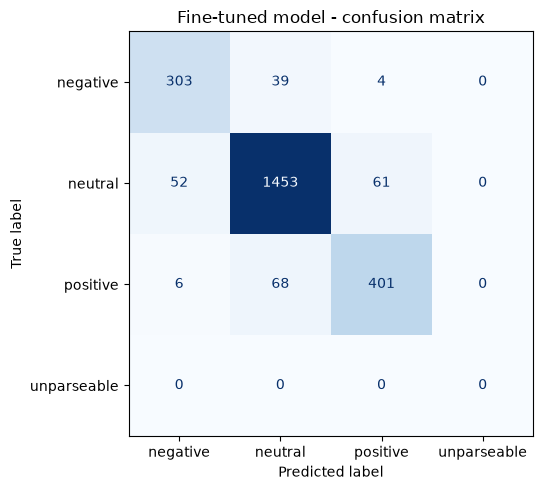

In [13]:
print("Per-class report (fine-tuned):\n")
print(classification_report(y_true, ft_preds, labels=LABELS, zero_division=0, digits=3))

cm_labels = LABELS + ["unparseable"]
cm = confusion_matrix(y_true, ft_preds, labels=cm_labels)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=cm_labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Fine-tuned model - confusion matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()


## 9. Error analysis

In [14]:
err = eval_clean.copy()
err["pred"] = ft_preds
err["raw_output"] = ft_raw
errors = err[err["label"] != err["pred"]]
print(f"Fine-tuned model errors: {len(errors)} / {len(err)}")

pd.set_option("display.max_colwidth", 120)
errors.sample(n=min(15, len(errors)), random_state=SEED)[["text", "label", "pred", "raw_output"]]


Fine-tuned model errors: 230 / 2387


,text,label,pred,raw_output
2134,"Hedge Funds Cashed Out Of Simpson Manufacturing Co, Inc. (SSD) Too Early",neutral,negative,negative
788,"Qatar, the world’s biggest supplier of liquefied natural gas, plans to boost output capacity by almost two thirds ht...",positive,neutral,neutral
113,"""There is every reason to believe that the economic rebound, when it comes, can be robust,"" Fed Chair Jerome Powell…...",positive,neutral,neutral
2034,$GDP - Goodrich Petroleum Corp.: A Solid Play. https://t.co/spGL5EIBuG #stockmarket #economy #stocks,neutral,positive,positive
184,Amazon blames holiday delivery delays on winter storms and high demand https://t.co/TjLnFZBE44,negative,neutral,neutral
2046,$MTN - Vail Resorts missing snow in early part of season https://t.co/K76oI960UO,neutral,negative,negative
220,Boeing : Deliveries 24 Jets in November #Boeing #Stock #MarketScreener https://t.co/jtBrv76jG6 https://t.co/s9q1BEhwcC,positive,neutral,neutral
2036,$GPRO strong action.,neutral,positive,positive
1637,China and U.S. 'very close' to phase one trade deal - Global Times https://t.co/t4idLxj9Bz https://t.co/oLkqruR3gU,neutral,positive,positive
1463,BPH Energy : Settlement of Litigation #BPHEnergy #Stock #MarketScreener https://t.co/DD5IfT4zgo https://t.co/sZfkzFWMcP,positive,neutral,neutral


## 10. Save results

In [15]:
summary = {
    "n_test_before_filter": int(len(eval_df)),
    "n_removed_as_overlap": n_leaked,
    "n_test_used": int(len(eval_clean)),
    "results": results.to_dict(orient="records"),
}
with open("eval_results.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))


{
  "n_test_before_filter": 2388,
  "n_removed_as_overlap": 1,
  "n_test_used": 2387,
  "results": [
    {
      "model": "Majority class (always 'neutral')",
      "accuracy": 0.6561,
      "macro_f1": 0.2641,
      "unparseable_pct": 0.0
    },
    {
      "model": "Base Llama-3.2-1B (adapter off)",
      "accuracy": 0.222,
      "macro_f1": 0.2888,
      "unparseable_pct": 35.2744
    },
    {
      "model": "Fine-tuned (QLoRA adapter)",
      "accuracy": 0.9036,
      "macro_f1": 0.8797,
      "unparseable_pct": 0.0
    }
  ]
}
